# LunarLander DQN — borrador de integración para el 2/11

**Estudio parcial: 24 de 32 combinaciones variante/semilla. No es la entrega final.**

Autores: Thiago, Fran y Agustín. Se incluyen las ocho corridas sin red objetivo de Thiago, ocho sin replay de Fran y las ocho semillas del completo. Faltan las ocho políticas sin exploración, los tests y el análisis de política de Agustín. La rama de Fran incluye 16 corridas; tres completas duplican semillas propias y se conservan como ejecuciones adicionales, fuera de este conjunto provisional. La referencia se arma con Thiago 42/1042/2042 y Fran 3042–7042, según disponibilidad y sin seleccionar por rendimiento; el equipo debe confirmar esta selección. El efecto de máquina/versiones limita la atribución causal entre condiciones.

Este notebook contiene el código del agente, las funciones de entrenamiento/evaluación, los CSV originales incorporados y un checkpoint representativo (completo, semilla 42, fijado sin seleccionar por rendimiento). Puede ejecutarse sin leer carpetas de resultados ni descargar pesos. Requiere las dependencias del proyecto. Reiniciar el kernel y ejecutar todas las celdas; no entrena por defecto. La discusión para el informe está en `ARQUITECTURA_METODOLOGIA.md`.

El notebook fuente usado en las corridas se conserva sin modificaciones en `lander.ipynb`.

## 1. Dependencias y entorno
Instalar las dependencias de `requirements.txt` en un entorno Python. Para reproducir las versiones de las corridas, consultar la tabla de configuración incorporada. La ejecución predeterminada verifica los datos, grafica y evalúa dos políticas; no inicia los 32 entrenamientos.

In [1]:
import base64, hashlib, inspect, io, json, random, zlib
from abc import ABC, abstractmethod
from collections import deque
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import time
from IPython.display import display, HTML
import html
torch.set_num_threads(1)
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
print('Gymnasium:', gym.__version__, '| PyTorch:', torch.__version__, '| dispositivo: CPU')

Gymnasium: 1.4.0 | PyTorch: 2.14.1 | dispositivo: CPU


## 2. Entorno
LunarLander-v3, discreto y sin viento: ocho observaciones y cuatro acciones. Éxito se define operacionalmente como retorno ≥ 200. La terminación real y el truncamiento por tiempo se distinguen al calcular el bootstrap.

In [2]:
env = gym.make('LunarLander-v3', continuous=False, enable_wind=False)
print('Observaciones:', env.observation_space.shape, '| Acciones:', env.action_space.n)
env.close()

Observaciones: (8,) | Acciones: 4


## 3. Agentes y funciones suministradas
Las definiciones se copian del notebook integrado, sin ejecutar sus demostraciones ni entrenamientos.

In [3]:
class Agente(ABC):

    @abstractmethod
    def elegir_accion(self, estado, explorar=True):
        """Elige una acción dada una observación. Con `explorar=False`, sin
        exploración: la acción que el agente considera mejor."""
        pass

    @abstractmethod
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Aprende de la experiencia."""
        pass

    def fin_episodio(self):
        """Callback opcional que el bucle de entrenamiento invoca al terminar cada
        episodio."""
        pass

class AgenteAleatorio(Agente):
    """Agente aleatorio que elige acciones al azar. Es la implementación de referencia."""

    def __init__(self, espacio_acciones, semilla=None):
        self.espacio_acciones = espacio_acciones
        if semilla is not None:
            espacio_acciones.seed(semilla)

    def elegir_accion(self, estado, explorar=True):
        return self.espacio_acciones.sample()

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        pass

In [4]:
UMBRAL_EXITO = 200.0

def evaluar_agente(agente, env, num_episodios=100, umbral_exito=UMBRAL_EXITO, semilla=None):
    """
    Evalúa el rendimiento de un agente a lo largo de múltiples episodios.

    Args:
        agente: El agente a evaluar
        env: El entorno
        num_episodios: Número de episodios a ejecutar
        umbral_exito: Recompensa mínima para considerar exitoso un episodio
        semilla: Si se indica, se usan semillas deterministas (semilla + i) para
                 que la comparación entre agentes use los mismos escenarios

    Returns:
        dict: Resultados de la evaluación
    """
    recompensas_totales = []
    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0
        while True:
            accion = agente.elegir_accion(estado, explorar=False)
            estado, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa
            if terminado or truncado:
                break
        recompensas_totales.append(recompensa_total)
    recompensas_totales = np.array(recompensas_totales)
    exitos = int((recompensas_totales >= umbral_exito).sum())
    return {'recompensas_totales': recompensas_totales, 'exitos': exitos, 'tasa_exito': exitos / num_episodios, 'recompensa_promedio': float(recompensas_totales.mean()), 'desv_estandar': float(recompensas_totales.std()), 'recompensa_mediana': float(np.median(recompensas_totales))}

def imprimir_resultados_evaluacion(resultados, nombre_agente):
    """Imprime los resultados de evaluación con formato."""
    print(f'\n{nombre_agente} - Resultados de evaluación:')
    print(f"Tasa de éxito (R ≥ {UMBRAL_EXITO:.0f}): {resultados['tasa_exito']:.1%}")
    print(f"Recompensa promedio: {resultados['recompensa_promedio']:.2f}")
    print(f"Recompensa mediana:  {resultados['recompensa_mediana']:.2f}")
    print(f"Desviación estándar: {resultados['desv_estandar']:.2f}")
    print(f"Total de éxitos: {resultados['exitos']} / {len(resultados['recompensas_totales'])}")

In [5]:
def entrenar_agente(agente, env, num_episodios=1000, max_pasos=1000, verbose=True, umbral_resolucion=None, semilla=None):
    """
    Entrena un agente en el entorno.

    Args:
        agente: El agente a entrenar
        env: El entorno
        num_episodios: Número de episodios de entrenamiento
        max_pasos: Máximo de pasos por episodio
        verbose: Si imprimir el progreso
        umbral_resolucion: Si se indica, corta cuando la media de las últimas 100
                           recompensas alcanza ese valor
        semilla: Semilla base para los reset (reproducibilidad)

    Returns:
        (list, list): recompensas y longitudes de cada episodio
    """
    recompensas_episodios = []
    longitudes_episodios = []
    cada = max(1, num_episodios // 20)
    t_inicio = time.time()
    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0
        pasos = 0
        for paso in range(max_pasos):
            accion = agente.elegir_accion(estado)
            siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)
            agente.aprender(estado, accion, recompensa, siguiente_estado, terminado)
            estado = siguiente_estado
            recompensa_total += recompensa
            pasos += 1
            if terminado or truncado:
                break
        agente.fin_episodio()
        recompensas_episodios.append(recompensa_total)
        longitudes_episodios.append(pasos)
        media_100 = np.mean(recompensas_episodios[-100:])
        if verbose and (episodio + 1) % cada == 0:
            print(f"Episodio {episodio + 1:5d} | Recompensa media (100 ep): {media_100:8.2f} | Longitud media: {np.mean(longitudes_episodios[-100:]):6.1f} | epsilon: {getattr(agente, 'epsilon', 0.0):.3f} | {time.time() - t_inicio:5.0f}s", flush=True)
        if umbral_resolucion is not None and len(recompensas_episodios) >= 100 and (media_100 >= umbral_resolucion):
            print(f'\n✓ Entorno resuelto en {episodio + 1} episodios (recompensa media de los últimos 100: {media_100:.2f})', flush=True)
            break
    print(f'Tiempo total de entrenamiento: {time.time() - t_inicio:.0f}s')
    return (recompensas_episodios, longitudes_episodios)

def media_movil(valores, ventana=100):
    """Media móvil causal, para suavizar las curvas de aprendizaje."""
    valores = np.asarray(valores, dtype=float)
    return np.array([valores[max(0, i - ventana + 1):i + 1].mean() for i in range(len(valores))])

def graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios, titulo='Progreso de entrenamiento', ventana=100):
    """Grafica el progreso del entrenamiento."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
    ax1.plot(recompensas_episodios, alpha=0.3, linewidth=0.8, label='Recompensa por episodio')
    ax1.plot(media_movil(recompensas_episodios, ventana), linewidth=2, label=f'Media móvil ({ventana} ep)')
    ax1.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1, label='Umbral de éxito (200)')
    ax1.axhline(0, color='black', linewidth=0.5)
    ax1.set_title(f'{titulo} - Recompensas')
    ax1.set_xlabel('Episodio')
    ax1.set_ylabel('Recompensa')
    ax1.legend(loc='lower right', fontsize=8)
    ax1.grid(True, alpha=0.3)
    ax2.plot(longitudes_episodios, alpha=0.3, linewidth=0.8)
    ax2.plot(media_movil(longitudes_episodios, ventana), linewidth=2)
    ax2.set_title(f'{titulo} - Longitud de los episodios')
    ax2.set_xlabel('Episodio')
    ax2.set_ylabel('Pasos')
    ax2.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 4. Agente DQN
Red 8 → 64 → 64 → 4, ReLU en capas ocultas. A0 usa Adam con learning rate 0.001. Se conserva la implementación integrada, incluidos los interruptores para las tres ablaciones.

In [6]:
# Toda la implementación del agente permanece dentro de AgenteDQN.
class AgenteDQN(Agente):
    """DQN integrado; cada componente se puede desactivar independientemente.

    Sin replay se usa solamente la transición actual (batch efectivo de uno),
    conservando el warmup y la frecuencia de actualizaciones de la referencia.
    """

    def __init__(self, estado_space, accion_space, semilla=None,
                 hidden_dims=(64, 64), lr=1e-3, use_target=True,
                 gamma=0.99, replay_capacity=50_000, batch_size=64,
                 learning_starts=1000, train_frequency=4, target_sync_steps=1000,
                 epsilon_start=1.0, epsilon_end=0.05, epsilon_decay_episodes=200,
                 gradient_clip=10.0, device="cpu", use_replay=True, use_exploration=True,
                 epsilon_schedule="linear_episodes", epsilon_decay_steps=50_000,
                 epsilon_decay_factor=0.995, target_update="hard", tau=1e-3):
        if any(type(value) is not bool for value in (use_target, use_replay, use_exploration)):
            raise ValueError("Los interruptores deben ser booleanos")
        if epsilon_schedule not in {"linear_episodes", "linear_steps", "exponential_episodes"}:
            raise ValueError("Esquema de exploración desconocido")
        if epsilon_decay_steps <= 0 or not 0 < epsilon_decay_factor <= 1:
            raise ValueError("Decaimiento de exploración inválido")
        if target_update not in {"hard", "soft"} or not 0 < tau <= 1:
            raise ValueError("Actualización de red objetivo inválida")
        if len(hidden_dims) != 2 or any(h <= 0 for h in hidden_dims):
            raise ValueError("Se requieren dos capas ocultas de tamaño positivo")
        if not (0 <= gamma <= 1 and 0 <= epsilon_end <= epsilon_start <= 1):
            raise ValueError("Descuento o epsilon inválido")
        if min(batch_size, learning_starts, train_frequency, target_sync_steps,
               epsilon_decay_episodes) <= 0 or replay_capacity < batch_size:
            raise ValueError("Capacidad, frecuencias o tamaño de batch inválidos")
        if lr <= 0 or gradient_clip <= 0:
            raise ValueError("lr y gradient_clip deben ser positivos")
        if semilla is not None:
            random.seed(semilla)
            np.random.seed(semilla)
            torch.manual_seed(semilla)
            accion_space.seed(semilla)
        self.accion_space = accion_space
        self.device = torch.device(device)
        self.use_target = use_target
        self.use_replay = use_replay
        self.use_exploration = use_exploration
        self.epsilon_schedule = epsilon_schedule
        self.epsilon_decay_steps = epsilon_decay_steps
        self.epsilon_decay_factor = epsilon_decay_factor
        self.target_update, self.tau = target_update, tau
        self.effective_batch_size = batch_size if use_replay else 1
        self.gamma = gamma
        self.batch_size = batch_size
        self.learning_starts = learning_starts
        self.train_frequency = train_frequency
        self.target_sync_steps = target_sync_steps
        self.epsilon_start, self.epsilon_end = epsilon_start, epsilon_end
        self.epsilon_decay_episodes = epsilon_decay_episodes
        self.gradient_clip = gradient_clip
        self.epsilon = epsilon_start if use_exploration else 0.0
        self.env_steps = self.optimizer_updates = self.completed_episodes = 0
        self.last_loss = None
        self.memoria = deque(maxlen=replay_capacity)
        dims = (int(np.prod(estado_space.shape)), *hidden_dims, accion_space.n)
        capas = []
        for i in range(len(dims) - 1):
            capas.append(nn.Linear(dims[i], dims[i + 1]))
            if i < len(dims) - 2:
                capas.append(nn.ReLU())
        self.red_q = nn.Sequential(*capas).to(self.device)
        if use_target:
            import copy
            self.red_objetivo = copy.deepcopy(self.red_q)
            self.red_objetivo.requires_grad_(False)
            self.red_objetivo.eval()
        self.optimizador = optim.Adam(self.red_q.parameters(), lr=lr,
                                      betas=(0.9, 0.999), eps=1e-8, weight_decay=0)

    def elegir_accion(self, estado, explorar=True):
        # El cortocircuito evita consumir RNG de exploración al evaluar.
        if explorar and self.use_exploration and random.random() < self.epsilon:
            return int(self.accion_space.sample())
        with torch.no_grad():
            tensor = torch.as_tensor(estado, dtype=torch.float32, device=self.device).reshape(1, -1)
            return int(self.red_q(tensor).argmax(dim=1).item())

    def _calcular_objetivos(self, siguientes, recompensas, terminados):
        with torch.no_grad():
            red = self.red_objetivo if self.use_target else self.red_q
            valores = red(siguientes).max(dim=1).values
            return recompensas + self.gamma * (~terminados).float() * valores

    def _actualizar_red(self, transiciones=None):
        if transiciones is None:
            transiciones = random.sample(self.memoria, self.batch_size)
        estados, acciones, recompensas, siguientes, terminados = zip(*transiciones)
        estados = torch.as_tensor(np.stack(estados), dtype=torch.float32, device=self.device)
        siguientes = torch.as_tensor(np.stack(siguientes), dtype=torch.float32, device=self.device)
        acciones = torch.as_tensor(acciones, dtype=torch.int64, device=self.device).unsqueeze(1)
        recompensas = torch.as_tensor(recompensas, dtype=torch.float32, device=self.device)
        terminados = torch.as_tensor(terminados, dtype=torch.bool, device=self.device)
        elegidos = self.red_q(estados).gather(1, acciones).squeeze(1)
        objetivos = self._calcular_objetivos(siguientes, recompensas, terminados)
        loss = F.smooth_l1_loss(elegidos, objetivos, beta=1.0, reduction="mean")
        self.optimizador.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(self.red_q.parameters(), self.gradient_clip)
        self.optimizador.step()
        self.optimizer_updates += 1
        self.last_loss = float(loss.detach().cpu())
        if self.use_target and self.target_update == "soft":
            with torch.no_grad():
                for objetivo, actual in zip(self.red_objetivo.parameters(), self.red_q.parameters()):
                    objetivo.mul_(1.0 - self.tau).add_(actual, alpha=self.tau)

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        transicion = (np.array(estado, dtype=np.float32, copy=True), int(accion),
                      float(recompensa), np.array(siguiente_estado, dtype=np.float32, copy=True),
                      bool(terminado))
        if self.use_replay:
            self.memoria.append(transicion)
        self.env_steps += 1
        if (self.env_steps >= self.learning_starts
                and self.env_steps % self.train_frequency == 0
                and (not self.use_replay or len(self.memoria) >= self.batch_size)):
            self._actualizar_red(None if self.use_replay else [transicion])
        if (self.use_target and self.target_update == "hard"
                and self.env_steps % self.target_sync_steps == 0):
            self.red_objetivo.load_state_dict(self.red_q.state_dict())
        if self.epsilon_schedule == "linear_steps":
            self.epsilon = self.epsilon_en(self.completed_episodes, self.env_steps)

    def epsilon_en(self, episodios, pasos):
        """Epsilon después del episodio/paso indicado; también se usa al guardar CSV."""
        if not self.use_exploration:
            return 0.0
        if self.epsilon_schedule == "exponential_episodes":
            return max(self.epsilon_end, self.epsilon_start * self.epsilon_decay_factor ** episodios)
        fraccion = (pasos / self.epsilon_decay_steps if self.epsilon_schedule == "linear_steps"
                    else episodios / self.epsilon_decay_episodes)
        return max(self.epsilon_end, self.epsilon_start -
                   (self.epsilon_start - self.epsilon_end) * min(fraccion, 1.0))

    def fin_episodio(self):
        self.completed_episodes += 1
        self.epsilon = self.epsilon_en(self.completed_episodes, self.env_steps)


## 5. Datos incorporados y trazabilidad
Los siguientes datos son una copia comprimida sin pérdida de configuración, resumen y todas las filas de entrenamiento/evaluación de las 24 políticas seleccionadas provisionalmente. Los pesos incorporados corresponden únicamente al agente completo de semilla 42. Los hashes del archivo del notebook difieren entre Windows y macOS únicamente por saltos de línea LF/CRLF; el archivo fuente versionado en Git es idéntico. Las versiones de paquetes y el hardware sí difieren, y se conservan por corrida.

In [7]:
RUNS = json.loads(zlib.decompress(base64.b64decode('...')))
PESOS = base64.b64decode('...')
assert hashlib.sha256(PESOS).hexdigest() == '49c4b10aac1ebd8aa0599676ea8b4938de6bccfe71d245c7b08c4a5d1b35d489'
print('Políticas incorporadas:', len(RUNS))

Políticas incorporadas: 24


In [8]:
def variante(config):
    desactivados = [k for k in ('use_target', 'use_replay', 'use_exploration') if not config[k]]
    assert len(desactivados) <= 1
    return {'use_target':'no_target', 'use_replay':'no_replay', 'use_exploration':'no_exploration'}[desactivados[0]] if desactivados else 'full'

vistos = set()
hashes = set()
for run in RUNS:
    c, s = run['config'], run['summary']
    key = (variante(c), c['training_seed'])
    assert key not in vistos
    vistos.add(key)
    hashes.add(c['source_notebook_sha256'])
    assert c['hidden_dims'] == [64, 64] and c['lr'] == .001
    assert c['episodes'] == s['completed_episodes'] == len(run['training']) == 300
    assert c['max_steps'] == 1000 and c['early_stopping'] is None
    assert c['evaluation_episodes'] == s['evaluated'] == len(run['evaluation']) == 200
    assert c['evaluation_seed'] == 10000 and c['evaluation_exploration'] is False
    assert [int(r['reset_seed']) for r in run['training']] == list(range(c['training_seed'], c['training_seed']+300))
    assert [int(r['reset_seed']) for r in run['evaluation']] == list(range(10000, 10200))
    retornos = np.array([float(r['return']) for r in run['evaluation']])
    assert np.isfinite(retornos).all() and np.isclose(retornos.mean(), s['mean_return'])
    assert int((retornos >= 200).sum()) == s['successes']
    assert sum(int(r['length']) for r in run['training']) == s['total_steps']
assert len(hashes) == 2 and len(vistos) == 24
assert hashes == {'06eb8e2e0b99c7569b2a33a6f5b1f6d35322b91b0b0f7e5ac8911afc543968c5', '8b02717c42f1bddd7a268b7de4798336adfdd9ba69a56e3d1fc079540b12df50'}
referencia = next(r for r in RUNS if variante(r['config']) == 'full' and r['config']['training_seed'] == 42)
print('Validación correcta: presupuesto, semillas, métricas, pasos y ausencia de duplicados en la selección.')
print('Revisión fuente:', referencia['config']['source_revision'])
print('SHA-256 archivos fuente (LF y CRLF):', sorted(hashes))
print('Versiones de las corridas:', json.dumps(referencia['config']['packages'], ensure_ascii=False))

Validación correcta: presupuesto, semillas, métricas, pasos y ausencia de duplicados en la selección.
Revisión fuente: 5bf74d4e86fc294341b7e74d0449af6ddb6b5131
SHA-256 archivos fuente (LF y CRLF): ['06eb8e2e0b99c7569b2a33a6f5b1f6d35322b91b0b0f7e5ac8911afc543968c5', '8b02717c42f1bddd7a268b7de4798336adfdd9ba69a56e3d1fc079540b12df50']
Versiones de las corridas: {"torch": "2.14.1", "gymnasium": "1.4.0", "numpy": "2.5.4", "matplotlib": "3.11.2", "Box2D": "2.3.10", "pygame-ce": "2.5.8"}


## 6. Protocolo y reproducción opcional
Las corridas usan 300 episodios de hasta 1000 pasos, sin parada anticipada; evaluación greedy del checkpoint final en 200 resets (10000–10199). Estas semillas ya se usaron para desarrollo. No se ha realizado la evaluación reservada 30000–30199. El acuerdo completo y el test deben confirmarse con los tres integrantes.

La siguiente función permite reentrenar desde cero, pero no se llama durante la ejecución normal. Los resultados nuevos no reemplazan los datos incorporados.

In [9]:
def reproducir_corrida(variante_nombre, semilla):
    cambios = {'full': {}, 'no_target': {'use_target': False},
               'no_replay': {'use_replay': False}, 'no_exploration': {'use_exploration': False}}
    config = referencia['config']
    firmas = inspect.signature(AgenteDQN.__init__).parameters
    parametros = {k: v for k, v in config.items() if k in firmas and k not in ('semilla', 'self')}
    parametros.update(cambios[variante_nombre])
    entorno = gym.make('LunarLander-v3', continuous=False, enable_wind=False)
    try:
        agente = AgenteDQN(entorno.observation_space, entorno.action_space, semilla=semilla, **parametros)
        retornos, longitudes = entrenar_agente(agente, entorno, num_episodios=300,
            max_pasos=1000, umbral_resolucion=None, semilla=semilla)
        evaluacion = evaluar_agente(agente, entorno, num_episodios=200, semilla=10000)
        return agente, retornos, longitudes, evaluacion
    finally:
        entorno.close()

REENTRENAR = False
if REENTRENAR:
    nueva_corrida = reproducir_corrida('full', 42)
else:
    print('Reentrenamiento desactivado; se analizan las corridas originales incorporadas.')

Reentrenamiento desactivado; se analizan las corridas originales incorporadas.


## 7. Curvas de aprendizaje
Media móvil causal de hasta 20 episodios. Cada línea representa una semilla. La comparación agregada usa las ocho semillas comunes; la banda es ±1 desviación estándar entre semillas, no un intervalo de confianza. Referencia y ablaciones incluyen distintos entornos de ejecución: interpretar las diferencias como descriptivas hasta revisar ese efecto con el equipo.

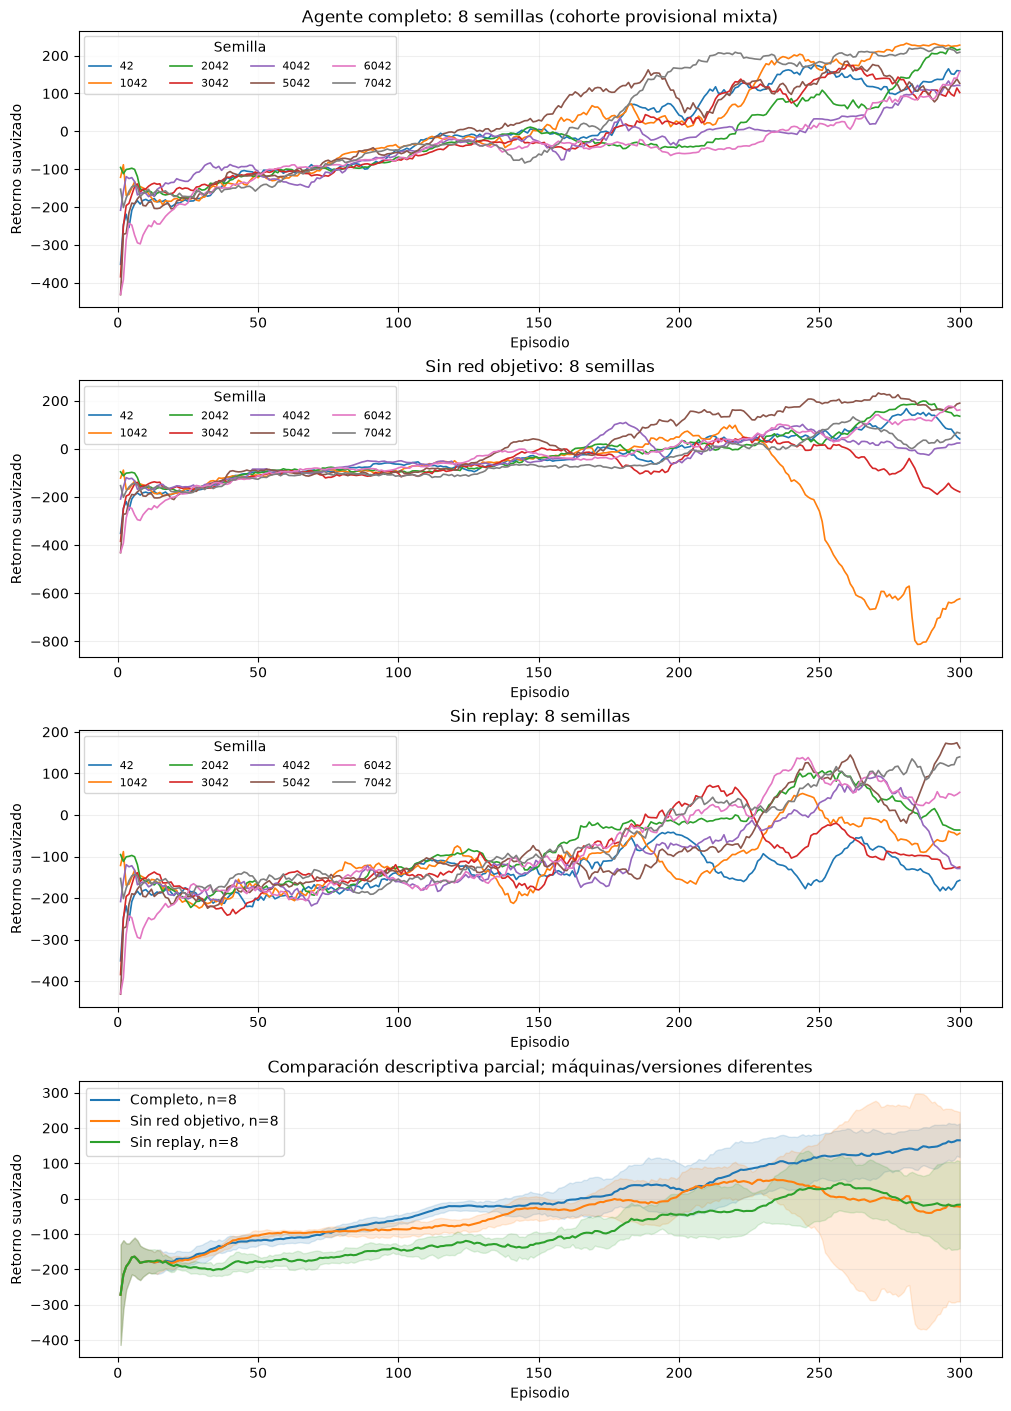

In [10]:
curvas = {(variante(r['config']), r['config']['training_seed']): media_movil(
    [float(f['return']) for f in r['training']], ventana=20) for r in RUNS}
comunes = sorted({s for v,s in curvas if v == 'full'} & {s for v,s in curvas if v == 'no_target'})
fig, axes = plt.subplots(4, 1, figsize=(10, 14), constrained_layout=True)
episodios = np.arange(1, 301)
for ax, v, titulo in [(axes[0], 'full', 'Agente completo: 8 semillas (cohorte provisional mixta)'), (axes[1], 'no_target', 'Sin red objetivo: 8 semillas'), (axes[2], 'no_replay', 'Sin replay: 8 semillas')]:
    for (condicion, semilla), valores in sorted(curvas.items()):
        if condicion == v:
            ax.plot(episodios, valores, label=str(semilla), linewidth=1.2)
    ax.set(title=titulo, xlabel='Episodio', ylabel='Retorno suavizado')
    ax.legend(title='Semilla', ncol=4, fontsize=8)
    ax.grid(alpha=.2)
for v, etiqueta in [('full', 'Completo'), ('no_target', 'Sin red objetivo'), ('no_replay', 'Sin replay')]:
    matriz = np.stack([curvas[v,s] for s in comunes])
    media, sd = matriz.mean(axis=0), matriz.std(axis=0, ddof=1)
    linea, = axes[3].plot(episodios, media, label=f'{etiqueta}, n={len(comunes)}')
    axes[3].fill_between(episodios, media-sd, media+sd, color=linea.get_color(), alpha=.15)
axes[3].set(title='Comparación descriptiva parcial; máquinas/versiones diferentes', xlabel='Episodio', ylabel='Retorno suavizado')
axes[3].legend()
axes[3].grid(alpha=.2)
plt.show()

## 8. Evaluación y baseline aleatorio
Se presentan métricas por política, sin tests inferenciales. Se recarga el checkpoint completo de semilla 42 y se comprueba su evaluación en las mismas semillas. El baseline aleatorio también se evalúa en esos resets. El checkpoint se fijó por su semilla, sin elegir el mejor resultado.

Condición,Semilla,Retorno medio,Éxitos R≥200,Pasos de entrenamiento
full,42,167.22,113/200,152500
full,1042,209.76,146/200,136486
full,2042,191.32,105/200,160541
full,3042,69.52,7/200,155482
full,4042,60.50,69/200,165167
full,5042,121.94,72/200,143546
full,6042,203.15,143/200,155138
full,7042,208.70,140/200,126703
no_replay,42,-28.18,1/200,91990
no_replay,1042,122.85,86/200,63829



Completo, semilla 42, reevaluación de desarrollo - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 56.5%
Recompensa promedio: 167.22
Recompensa mediana:  212.44
Desviación estándar: 103.12
Total de éxitos: 113 / 200

Baseline aleatorio, desarrollo - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -183.17
Recompensa mediana:  -149.80
Desviación estándar: 111.96
Total de éxitos: 0 / 200


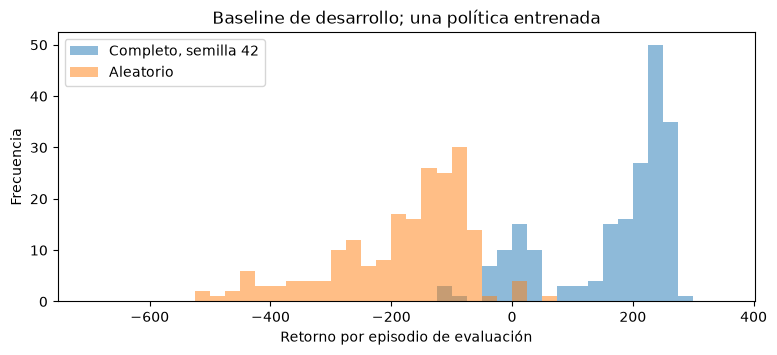

In [11]:
filas = []
for r in sorted(RUNS, key=lambda r: (variante(r['config']), r['config']['training_seed'])):
    c, s = r['config'], r['summary']
    filas.append(f"<tr><td>{html.escape(variante(c))}</td><td>{c['training_seed']}</td><td>{s['mean_return']:.2f}</td><td>{s['successes']}/{s['evaluated']}</td><td>{s['total_steps']}</td></tr>")
display(HTML('<table><tr><th>Condición</th><th>Semilla</th><th>Retorno medio</th><th>Éxitos R≥200</th><th>Pasos de entrenamiento</th></tr>' + ''.join(filas) + '</table>'))
entorno = gym.make('LunarLander-v3', continuous=False, enable_wind=False)
try:
    politica = AgenteDQN(entorno.observation_space, entorno.action_space, semilla=42)
    politica.red_q.load_state_dict(torch.load(io.BytesIO(PESOS), map_location='cpu', weights_only=True))
    politica.red_q.eval()
    originales = {k: v.clone() for k,v in politica.red_q.state_dict().items()}
    evaluacion = evaluar_agente(politica, entorno, num_episodios=200, semilla=10000)
    assert np.allclose(evaluacion['recompensas_totales'], [float(r['return']) for r in referencia['evaluation']], atol=1e-4, rtol=1e-6), 'La reevaluación difiere: revisar versiones/dispositivo antes de reemplazar datos históricos.'
    assert politica.env_steps == politica.optimizer_updates == 0
    assert all(torch.equal(v, originales[k]) for k,v in politica.red_q.state_dict().items())
    azar = AgenteAleatorio(entorno.action_space, semilla=42)
    evaluacion_azar = evaluar_agente(azar, entorno, num_episodios=200, semilla=10000)
finally:
    entorno.close()
imprimir_resultados_evaluacion(evaluacion, 'Completo, semilla 42, reevaluación de desarrollo')
imprimir_resultados_evaluacion(evaluacion_azar, 'Baseline aleatorio, desarrollo')
fig, ax = plt.subplots(figsize=(9, 3.5))
for resultado, etiqueta in [(evaluacion, 'Completo, semilla 42'), (evaluacion_azar, 'Aleatorio')]:
    ax.hist(resultado['recompensas_totales'], bins=np.linspace(-700, 350, 43), alpha=.5, label=etiqueta)
ax.set(xlabel='Retorno por episodio de evaluación', ylabel='Frecuencia', title='Baseline de desarrollo; una política entrenada')
ax.legend()
plt.show()

## 9. Rollouts y visualizaciones
**Pendiente de integración con Agustín.** Incorporar los rollouts/GIF acordados y registrar las semillas de evaluación y el checkpoint utilizado. Los pesos completos de semilla 42 están incorporados para permitir visualización sin descargar archivos.

## 10. Cortes de política
**Pendiente de Agustín.** Incorporar código, salidas y valores fijos de los cortes; identificar el checkpoint. Los estados sintéticos pueden ser inalcanzables y Q no es una probabilidad. La discusión debe ir en el informe.

## 11. Ablaciones: cobertura y análisis pendiente
La unidad experimental es la política entrenada con una semilla. Los episodios de evaluación no son réplicas independientes del entrenamiento. La lista siguiente muestra faltantes reales; no se sustituyen por pilotos. Fran debe aportar los tests de las tres comparaciones y la corrección acordada antes de cerrar conclusiones.

In [12]:
planeadas = {42,1042,2042,3042,4042,5042,6042,7042}
for v in ['full', 'no_target', 'no_replay', 'no_exploration']:
    disponibles = {s for condicion,s in vistos if condicion == v}
    print(f'{v}: {len(disponibles)}/8; faltan {sorted(planeadas-disponibles)}')
print('Estadística inferencial: pendiente. Evaluación reservada: no realizada.')

full: 8/8; faltan []
no_target: 8/8; faltan []
no_replay: 8/8; faltan []
no_exploration: 0/8; faltan [42, 1042, 2042, 3042, 4042, 5042, 6042, 7042]
Estadística inferencial: pendiente. Evaluación reservada: no realizada.


## 12. Revisión de entrega
Antes de entregar: completar las 32 corridas y las secciones 9–11, incorporar el método estadístico acordado, revisar referencias y el informe IEEE (máximo 5 páginas), reiniciar el kernel y ejecutar todo nuevamente. La ejecución de este borrador no acredita la entrega final.